# NHL: анализ статистики команд

**Тестовое задание • 100 баллов**

Вы аналитик, которому передали готовую таблицу с исторической статистикой команд NHL.
Изучите данные, проверьте их, постройте графики и объясните свои наблюдения.
В работе оцениваются чтение данных, анализ, графики и обоснованность выводов.

Ориентир времени: 3-5 часов (знание хоккея не требуется).
Можно обращаться к документации и пользоваться вспомогательными инструментами.
Укажите, чем пользовались; отвечайте за правильность и понимание сданной работы.
Подтверждайте ответы результатами из своего ноутбука.

## Что сдавать

Выполненный IPynb с видимыми результатами и ответами разместите на платформе githib.com.
Укажите имя, дату и используемые инструменты укажите в README.
Файл `data/hockey_raw.csv` уже приложен к заданию. Исходный файл сохраняйте без изменений.
Для развёрнутого ответа обычно достаточно 3-6 содержательных предложений.
Каждый такой ответ должен ссылаться на ваши числа, строки или графики.

## Данные

Одна строка соответствует одной команде в одном сезоне. Значение `year` является
меткой сезона на сайте. Источник готовой таблицы:
[Scrape This Site - Hockey Teams](https://www.scrapethissite.com/pages/forms/).
Работайте с приложенным CSV; обращения к сайту для выполнения задания не нужны.

| Столбец | Значение |
|---|---|
| `team` | Название команды |
| `year` | Метка сезона |
| `wins` | Победы |
| `losses` | Поражения |
| `ot_losses` | Поражения в дополнительное время, если значение указано |
| `win_rate` | Доля побед, указанная в источнике |
| `goals_for` | Забитые шайбы |
| `goals_against` | Пропущенные шайбы |
| `goal_diff` | Разница забитых и пропущенных шайб |

Пустое значение в `ot_losses` рассматривайте как пропуск.
Для графиков указывайте заголовок и подписи осей с единицами измерения.
При объяснении причин отделяйте то, что видно в таблице, от предположений.

## Баллы

| Раздел | Баллы |
|---|---:|
| 1. Загрузка и проверка | 25 |
| 2. Таблицы и группировка | 25 |
| 3. Графики | 30 |
| 4. Интерпретация | 20 |
| **Всего** | **100** |

Выполняйте пункты по порядку. Каждый пункт оценивается отдельно.

CSV выгружен из таблицы [Scrape This Site](https://www.scrapethissite.com/pages/forms/).
Исходные значения сохранены без изменений, пустые ячейки оставлены пустыми.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

## 1.1. Загрузите таблицу: 5 баллов

Прочитайте приложенный CSV в pandas. Покажите первые пять строк,
        число строк и столбцов. Какие наблюдения представляет одна строка?

In [2]:
hockey_data = pd.read_csv("data/hockey_raw.csv")
display(hockey_data.head())
print(f"Строк: {hockey_data.shape[0]}, столбцов: {hockey_data.shape[1]}")


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14
2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25


Строк: 582, столбцов: 9


**Ответ 1.1:**

Загружено **582 строки и 9 столбцов**. Одна строка описывает одну команду в одном сезоне. Например, первая строка - Boston Bruins, 1990 год: 44 победы и доля побед 0.550.


## 1.2. Разберитесь со столбцами: 6 баллов

Выведите названия и типы столбцов. Посчитайте число разных команд и годов.
        Проверьте, повторяется ли пара `team` и `year`. Объясните результат проверки.

In [3]:
display(hockey_data.dtypes.to_frame("Тип"))
print("Разных команд:", hockey_data["team"].nunique())
print("Разных годов:", hockey_data["year"].nunique())
print("Повторов (team, year):", hockey_data.duplicated(["team", "year"]).sum())


,Тип
team,str
year,int64
wins,int64
losses,int64
ot_losses,float64
win_rate,float64
goals_for,int64
goals_against,int64
goal_diff,int64


Разных команд: 35
Разных годов: 21
Повторов (team, year): 0


**Ответ 1.2:**

В таблице **35 названий команд и 21 год**. `team` имеет тип `object`, `win_rate` и `ot_losses` — `float64`, остальные столбцы — `int64`. Повторов пары `(team, year)` **0**, поэтому такая пара однозначно определяет строку.


## 1.3. Найдите пропуски: 8 баллов

Посчитайте число и долю пропусков по столбцам. Для `ot_losses` покажите
        число пропусков по годам. Как будете обращаться с этим полем в дальнейшем анализе
        и почему?

In [4]:
display(pd.DataFrame({
    "Число пропусков": hockey_data.isna().sum(),
    "Доля пропусков": hockey_data.isna().mean(),
}))
display(hockey_data.groupby("year")["ot_losses"].apply(lambda values: values.isna().sum())
        .to_frame("Пропуски ot_losses"))


,Число пропусков,Доля пропусков
team,0,0.00000
year,0,0.00000
wins,0,0.00000
losses,0,0.00000
ot_losses,224,0.38488
win_rate,0,0.00000
goals_for,0,0.00000
goals_against,0,0.00000
goal_diff,0,0.00000


,Пропуски ot_losses
year,
1990,21
1991,22
1992,24
1993,26
1994,26
1995,26
1996,26
1997,26
1998,27


**Ответ 1.3:**

В `ot_losses` **224 пропуска, или 38.49% строк**, в остальных столбцах пропусков нет. За 1990–1998 годы все значения `ot_losses` пусты, начиная с 1999 года пропусков нет. Оставлю их как `NaN`, поскольку пропуск не означает ноль. В дальнейшем использую заполненные показатели, поэтому удалять строки не нужно.


## 1.4. Проверьте согласованность: 6 баллов

Проверьте, что `win_rate` лежит между 0 и 1, счётчики побед и голов
        неотрицательны, а `goal_diff` равен `goals_for - goals_against`.
        Сообщите, сколько строк нарушает каждое условие. Как бы вы поступили,
        если бы обнаружили нарушение?

In [5]:
check_results = pd.Series({
    "win_rate вне [0, 1]": (~hockey_data["win_rate"].between(0, 1)).sum(),
    "wins < 0": (hockey_data["wins"] < 0).sum(),
    "goals_for < 0": (hockey_data["goals_for"] < 0).sum(),
    "goals_against < 0": (hockey_data["goals_against"] < 0).sum(),
    "Несовпадение goal_diff": (hockey_data["goal_diff"] != hockey_data["goals_for"] - hockey_data["goals_against"]).sum(),
})
display(check_results.to_frame("Число нарушений"))


,Число нарушений
"win_rate вне [0, 1]",0
wins < 0,0
goals_for < 0,0
goals_against < 0,0
Несовпадение goal_diff,0


**Ответ 1.4:**

По всем пяти условиям получено **0 нарушений**. Доля побед входит в [0, 1], победы и голы неотрицательны, разница шайб во всех строках рассчитана верно. При нарушении сверил бы строку с источником, а исправление сделал бы в рабочей копии, сохранив исходный CSV.


## 2.1. Опишите долю побед: 6 баллов

Найдите минимум, медиану, среднее и максимум `win_rate` по всей таблице.
        Сравните медиану и среднее. Что эти числа сообщают о типичном командном сезоне,
        а чего по ним узнать нельзя?

In [6]:
win_rate_stats = hockey_data["win_rate"].agg(["min", "median", "mean", "max"])
display(win_rate_stats.to_frame("win_rate"))


,win_rate
min,0.119000
median,0.463000
mean,0.458519
max,0.756000


**Ответ 2.1:**

Минимум доли побед — **0.119**, медиана — **0.463**, среднее — **0.458519**, максимум — **0.756**. Среднее немного ниже медианы, но оба показателя указывают на типичную долю около 46%. Эти числа не показывают историю отдельных команд и причины различий между сезонами.


## 2.2. Сравните сезоны: 8 баллов

Для каждого года посчитайте число команд, медиану `wins` и медиану `win_rate`.
        Выведите таблицу целиком и отдельно сравните 1993, 1994 и 1995 годы.
        Как отличается картина по числу побед и по доле побед?

In [7]:
season_stats = hockey_data.groupby("year").agg(
    teams=("team", "nunique"),
    median_wins=("wins", "median"),
    median_win_rate=("win_rate", "median"),
)
display(season_stats)
display(season_stats.loc[[1993, 1994, 1995]])


,teams,median_wins,median_win_rate
year,,,
1990,21,34.0,0.4250
1991,22,35.5,0.4440
1992,24,40.0,0.4760
1993,26,39.0,0.4640
1994,26,20.5,0.4275
1995,26,35.5,0.4330
1996,26,35.0,0.4270
1997,26,35.0,0.4270
1998,27,34.0,0.4150


,teams,median_wins,median_win_rate
year,,,
1993,26,39.0,0.4640
1994,26,20.5,0.4275
1995,26,35.5,0.4330


**Ответ 2.2:**

В 1993, 1994 и 1995 годах представлено по **26 команд**; медианы побед — **39.0, 20.5 и 35.5**, медианы доли побед — **0.4640, 0.4275 и 0.4330**. В 1994 году медиана числа побед почти вдвое меньше, чем в 1993-м, но медиана доли ниже только на **3.65 процентного пункта**. Это может быть связано с меньшим количеством матчей, поэтому сравнивать только число побед неудобно; причина в таблице не указана.


## 2.3. Найдите крайние результаты: 5 баллов

Покажите три строки с самой высокой и три с самой низкой `win_rate`.
        Укажите команду, год и значение. Как вы убедились, что сравниваете именно долю,
        а не число побед?

In [8]:
selected_columns = ["team", "year", "win_rate"]
print("Три наибольшие доли побед:")
display(hockey_data.nlargest(3, "win_rate")[selected_columns])
print("Три наименьшие доли побед:")
display(hockey_data.nsmallest(3, "win_rate")[selected_columns])


Три наибольшие доли побед:


,team,year,win_rate
126,Detroit Red Wings,1995,0.756
382,Detroit Red Wings,2005,0.707
99,Detroit Red Wings,1994,0.688


Три наименьшие доли побед:


,team,year,win_rate
56,Ottawa Senators,1992,0.119
60,San Jose Sharks,1992,0.131
82,Ottawa Senators,1993,0.167


**Ответ 2.3:**

Три максимума принадлежат Detroit Red Wings: **1995 — 0.756, 2005 — 0.707, 1994 — 0.688**. Минимумы: **Ottawa Senators, 1992 — 0.119; San Jose Sharks, 1992 — 0.131; Ottawa Senators, 1993 — 0.167**. В `nlargest` и `nsmallest` явно указан столбец `win_rate`, поэтому сравниваются доли, а не количество побед.


## 2.4. Выберите команду: 6 баллов

Выберите команду, представленную не менее чем в пяти сезонах.
        Покажите её строки по годам и найдите сезон с минимальной и максимальной
        долей побед. Почему сравнивать только название команды без года неудобно?

In [9]:
detroit_seasons = hockey_data[hockey_data["team"] == "Detroit Red Wings"].sort_values("year")
display(detroit_seasons)
print("Минимальная и максимальная доли побед:")
display(detroit_seasons.loc[
    [detroit_seasons["win_rate"].idxmin(), detroit_seasons["win_rate"].idxmax()], selected_columns
])


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25
25,Detroit Red Wings,1991,43,25,NaN,0.537,320,256,64
47,Detroit Red Wings,1992,47,28,NaN,0.560,369,280,89
73,Detroit Red Wings,1993,46,30,NaN,0.548,356,275,81
99,Detroit Red Wings,1994,33,11,NaN,0.688,180,117,63
126,Detroit Red Wings,1995,62,13,NaN,0.756,325,181,144
152,Detroit Red Wings,1996,38,26,NaN,0.463,253,197,56
179,Detroit Red Wings,1997,44,23,NaN,0.537,250,196,54
205,Detroit Red Wings,1998,43,32,NaN,0.524,245,202,43
233,Detroit Red Wings,1999,48,22,2.0,0.585,278,210,68


Минимальная и максимальная доли побед:


,team,year,win_rate
4,Detroit Red Wings,1990,0.425
126,Detroit Red Wings,1995,0.756


**Ответ 2.4:**

Detroit Red Wings представлена в **21 сезоне**, что больше требуемых пяти. Минимальная доля побед — **0.425 в 1990 году**, максимальная — **0.756 в 1995 году**. Без года название команды выбирает сразу много разных результатов, поэтому сравнение становится неоднозначным.


## 3.1. Покажите распределение: 7 баллов

Постройте гистограмму `win_rate` для всех строк.
        Подпишите оси и объясните, в какой части шкалы расположено большинство наблюдений.
        Приведите числовое подтверждение из пункта 2.1.

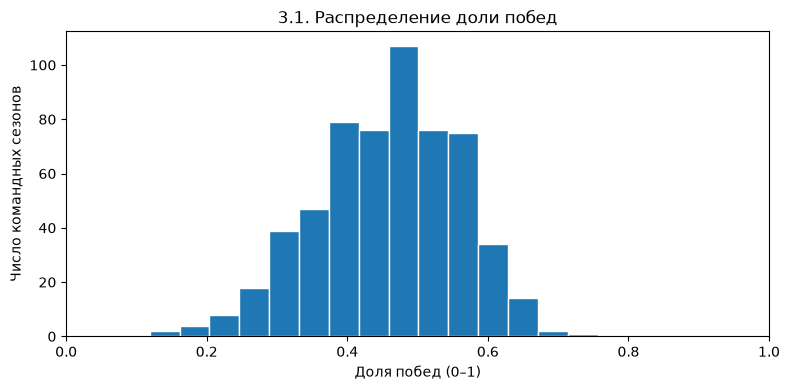

In [10]:
plt.figure(figsize=(8, 4))
plt.hist(hockey_data["win_rate"], bins=15, edgecolor="white")
plt.title("3.1. Распределение доли побед")
plt.xlabel("Доля побед (0–1)")
plt.ylabel("Число командных сезонов")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()


**Ответ 3.1:**

На гистограмме 3.1 большинство наблюдений находится в средней части шкалы. Это согласуется с **медианой 0.463 и средним 0.458519** из пункта 2.1. Крайние значения 0.119 и 0.756 не характеризуют типичный сезон.


## 3.2. Покажите изменение по годам: 8 баллов

Постройте линейный график медианы `win_rate` по годам из пункта 2.2.
        Подпишите оси. Найдите один год с заметно большей или меньшей медианой,
        чем у соседних доступных лет, и приведите числа. Отметьте в объяснении
        годы без данных.

,median_win_rate
year,
2009,0.488
2010,0.524
2011,0.500


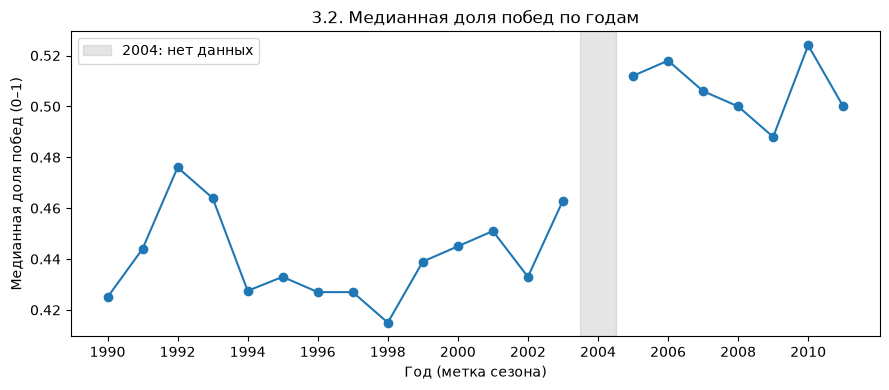

In [11]:
year_range = range(hockey_data["year"].min(), hockey_data["year"].max() + 1)
season_win_rates = season_stats["median_win_rate"].reindex(year_range)
display(season_stats.loc[[2009, 2010, 2011], ["median_win_rate"]])

plt.figure(figsize=(9, 4))
plt.plot(season_win_rates.index, season_win_rates, marker="o")
plt.axvspan(2003.5, 2004.5, color="grey", alpha=0.2, label="2004: нет данных")
plt.title("3.2. Медианная доля побед по годам")
plt.xlabel("Год (метка сезона)")
plt.ylabel("Медианная доля побед (0–1)")
plt.xticks(range(1990, 2012, 2))
plt.legend()
plt.tight_layout()
plt.show()


**Ответ 3.2:**

Медиана **2010 года — 0.524**, выше соседних: **2009 — 0.488, 2011 — 0.500**. Разница составляет соответственно **3.6 и 2.4 процентного пункта**. За **2004 год данных нет**: на графике 3.2 он добавлен с `NaN`, поэтому линия разорвана, а пропуск выделен серым.


## 3.3. Сравните голы и долю побед: 8 баллов

Постройте диаграмму рассеяния: `goal_diff` по горизонтали,
        `win_rate` по вертикали. Опишите общую связь и приведите две конкретные
        строки для иллюстрации. Можно ли по этому графику заключить, что знак
        `goal_diff` безошибочно определяет высокую долю побед?

Корреляция: 0.887


,team,year,goal_diff,win_rate
98,Dallas Stars,1994,1,0.354
126,Detroit Red Wings,1995,144,0.756


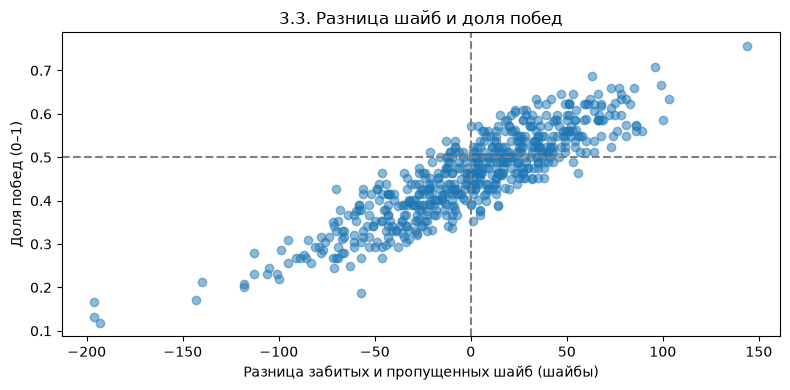

In [12]:
goals_wins_correlation = hockey_data["goal_diff"].corr(hockey_data["win_rate"])
print(f"Корреляция: {goals_wins_correlation:.3f}")
comparison_rows = hockey_data[
    ((hockey_data["team"] == "Detroit Red Wings") & (hockey_data["year"] == 1995)) |
    ((hockey_data["team"] == "Dallas Stars") & (hockey_data["year"] == 1994))
]
display(comparison_rows[["team", "year", "goal_diff", "win_rate"]])

plt.figure(figsize=(8, 4))
plt.scatter(hockey_data["goal_diff"], hockey_data["win_rate"], alpha=0.5)
plt.axvline(0, color="grey", linestyle="--")
plt.axhline(0.5, color="grey", linestyle="--")
plt.title("3.3. Разница шайб и доля побед")
plt.xlabel("Разница забитых и пропущенных шайб (шайбы)")
plt.ylabel("Доля побед (0–1)")
plt.tight_layout()
plt.show()


**Ответ 3.3:**

На диаграмме 3.3 видна положительная связь, корреляция составляет **0.887**. У **Detroit Red Wings, 1995** разница шайб **+144** и доля побед **0.756**, у **Dallas Stars, 1994** — **+1** и **0.354**. Если считать высокой долю не менее 0.5, пример Dallas показывает, что положительный знак разницы шайб её не гарантирует.


## 3.4. Покажите историю выбранной команды: 7 баллов

Для команды из пункта 2.4 постройте график `win_rate` по годам.
        Укажите в ответе, есть ли годы без данных, и как вы показали их на графике.
        Найдите два соседних доступных сезона с заметным изменением
        и укажите значения в ответе.

,team,year,win_rate
126,Detroit Red Wings,1995,0.756
152,Detroit Red Wings,1996,0.463


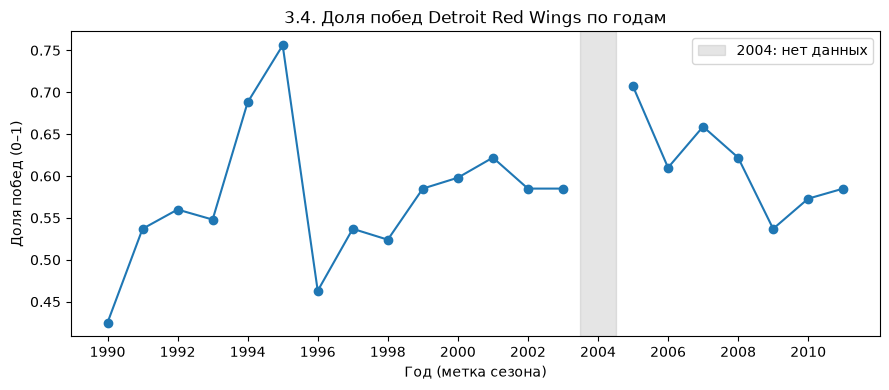

In [13]:
detroit_win_rates = detroit_seasons.set_index("year")["win_rate"].reindex(year_range)
display(detroit_seasons.loc[detroit_seasons["year"].isin([1995, 1996]), selected_columns])

plt.figure(figsize=(9, 4))
plt.plot(detroit_win_rates.index, detroit_win_rates, marker="o")
plt.axvspan(2003.5, 2004.5, color="grey", alpha=0.2, label="2004: нет данных")
plt.title("3.4. Доля побед Detroit Red Wings по годам")
plt.xlabel("Год (метка сезона)")
plt.ylabel("Доля побед (0–1)")
plt.xticks(range(1990, 2012, 2))
plt.legend()
plt.tight_layout()
plt.show()


**Ответ 3.4:**

На графике 3.4 отсутствует **2004 год**: значение `NaN` разрывает линию, серый фон отмечает пропуск. В соседних доступных сезонах **1995 и 1996** доля побед падает с **0.756 до 0.463**. Снижение составляет **29.3 процентного пункта**, что подтверждают показанные строки команды.


## 4.1. Проверьте последовательность лет: 5 баллов

Найдите все годы между минимальным и максимальным `year`,
        которых нет в таблице. Как отсутствие года может повлиять на линейный график?
        Сошлитесь на свой график из пункта 3.2.

In [14]:
unavailable_years = sorted(set(year_range) - set(hockey_data["year"]))
print("Отсутствующие годы:", unavailable_years)


Отсутствующие годы: [2004]


**Ответ 4.1:**

В диапазоне **1990–2011** отсутствует только **2004 год**. Если не добавить этот год с `NaN`, линия напрямую соединит 2003 и 2005 годы, скрывая отсутствие промежуточного наблюдения. На графике 3.2 вместо этого показан разрыв.


## 4.2. Сравните число побед и долю: 6 баллов

Возьмите одну команду, которая есть в 1993, 1994 и 1995 годах.
        Выведите для неё `wins` и `win_rate` за эти годы.
        Какой вывод изменится, если смотреть только на число побед?
        Свяжите ответ с группировкой из пункта 2.2.

In [15]:
display(detroit_seasons.loc[
    detroit_seasons["year"].isin([1993, 1994, 1995]), ["team", "year", "wins", "win_rate"]
])


,team,year,wins,win_rate
73,Detroit Red Wings,1993,46,0.548
99,Detroit Red Wings,1994,33,0.688
126,Detroit Red Wings,1995,62,0.756


**Ответ 4.2:**

У Detroit Red Wings в 1993, 1994 и 1995 годах соответственно **46, 33 и 62 победы**, доли — **0.548, 0.688 и 0.756**. Только по победам 1994 год выглядит хуже 1993-го, хотя доля побед выросла на **14 процентных пунктов**. В пункте 2.2 также видно сильное падение медианы числа побед — с **39 до 20.5**, поэтому эти два показателя нельзя подменять друг другом.


## 4.3. Найдите собственное наблюдение: 5 баллов

Найдите ещё один интересный вам пример в таблице или на графике.
        Укажите команду, год, два значения и пункт, результат которого
        помог вам заметить пример. Как он уточняет ваш общий вывод?

In [16]:
lightning_season = hockey_data[(hockey_data["team"] == "Tampa Bay Lightning") & (hockey_data["year"] == 2006)]
display(lightning_season[["team", "year", "goal_diff", "win_rate"]])


,team,year,goal_diff,win_rate
428,Tampa Bay Lightning,2006,-8,0.537


**Ответ 4.3:**

У **Tampa Bay Lightning в 2006 году** разница шайб **−8**, но доля побед **0.537**. Пример замечен среди точек с отрицательной разницей шайб выше уровня 0.5 на диаграмме 3.3. Он уточняет общий вывод: отрицательная разница не исключает победы более чем в половине матчей.


## 4.4. Сформулируйте выводы: 4 баллов

Сформулируйте два вывода из своей работы. Для каждого приведите
        номер таблицы или графика и одно число. Назовите одно ограничение данных,
        которое важно помнить при чтении результатов.

**Ответ 4.4:**

Первый вывод: типичная доля побед около 46%, что подтверждает **медиана 0.463** в таблице 2.1 и гистограмма 3.1. Второй вывод: разница шайб связана с долей побед, но не определяет её безошибочно — корреляция в пункте 3.3 равна **0.887**, а у Dallas при разнице +1 доля лишь 0.354. Ограничение данных: **2004 год отсутствует**, поэтому на графиках 3.2 и 3.4 есть разрыв.
